<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session14_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۴: پروژهٔ پایانی، پیش‌بینی پاسخ مشتری به تماس بازاریابی بانک

در این جلسه همهٔ چیزهایی را که در این ترم یاد گرفتیم، روی یک مسئلهٔ واقعی کسب‌وکار کنار هم می‌گذاریم: از تعریف مسئله و شناخت داده تا انتخاب مدل، تصمیم‌گیری بر اساس سود و زیان، تفسیر مدل و ذخیرهٔ آن برای استفاده در یک محصول.

### اهداف این جلسه

- تبدیل یک سؤال کسب‌وکار به یک مسئلهٔ یادگیری ماشین با معیار موفقیت روشن
- تشخیص **نشت هدف** در یک دادهٔ واقعی
- ساختن Pipeline کامل و مقایسهٔ منصفانهٔ چند مدل با اعتبارسنجی متقابل
- تنظیم ابرپارامتر مدل منتخب
- انتخاب آستانهٔ تصمیم بر اساس **سود مورد انتظار**، نه دقت
- تفسیر مدل با Permutation Importance و نمودار وابستگی جزئی
- ذخیره و بارگذاری مدل نهایی برای استفاده در یک برنامه

## ۱. مسئله

یک بانک پرتغالی برای فروش **سپردهٔ بلندمدت** با مشتریان تماس تلفنی می‌گیرد. هر تماس هزینه دارد (وقت کارمند مرکز تماس) و بیشتر مشتریان جواب منفی می‌دهند. مدیر بازاریابی می‌پرسد:

> «قبل از کمپین بعدی، می‌توانیم بفهمیم با چه کسانی تماس بگیریم تا با هزینهٔ کمتر، سپردهٔ بیشتری بفروشیم؟»

**تعریف مسئلهٔ یادگیری ماشین:**
- **هدف:** ستون `y`؛ آیا مشتری سپرده را خریده است (`yes`) یا نه (`no`). یک مسئلهٔ طبقه‌بندی دودویی.
- **لحظهٔ پیش‌بینی:** **قبل از** تماس. پس فقط از اطلاعاتی می‌توانیم استفاده کنیم که قبل از تماس در دسترس است.
- **معیار موفقیت فنی:** چون کلاس مثبت نادر است، **Average Precision** (سطح زیر منحنی Precision-Recall) و ROC AUC.
- **معیار موفقیت کسب‌وکار:** **سود کمپین**. فرض می‌کنیم هر تماس ۵ واحد هزینه دارد و هر سپردهٔ فروخته‌شده ۵۰ واحد سود.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
bank = pd.read_csv(DATA_URL + "bank_marketing.csv")
print(bank.shape)
bank.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. شناخت داده

داده‌ها از کمپین‌های واقعی این بانک بین سال‌های ۲۰۰۸ تا ۲۰۱۰ جمع شده‌اند (Moro و همکاران، ۲۰۱۴). ستون‌ها چهار گروه‌اند:

| گروه | ستون‌ها |
|---|---|
| مشتری | `age`، `job`، `marital`، `education`، `default`، `housing`، `loan` |
| تماس فعلی | `contact`، `month`، `day_of_week`، `duration` |
| سابقهٔ کمپین | `campaign` (تعداد تماس در این کمپین)، `pdays` (روز از آخرین تماس قبلی؛ ۹۹۹ یعنی هرگز)، `previous`، `poutcome` |
| شاخص‌های اقتصادی | `emp_var_rate`، `cons_price_idx`، `cons_conf_idx`، `euribor3m` (نرخ بهرهٔ بین‌بانکی)، `nr_employed` |

</div>

In [2]:
bank["y"] = (bank["y"] == "yes").astype(int)
print(f"Subscription rate: {bank['y'].mean():.1%}")
print("Missing values:", bank.isna().sum().sum())
(bank == "unknown").sum().loc[lambda s: s > 0]

Subscription rate: 11.3%
Missing values: 0


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- فقط حدود ۱۱٪ مشتریان سپرده خریده‌اند؛ داده به‌شدت **نامتوازن** است.
- مقدار گمشده به شکل `NaN` نداریم، ولی چند ستون دسته‌ای مقدار `unknown` دارند. برای ستون‌های دسته‌ای، `unknown` را یک دستهٔ جداگانه نگه می‌داریم؛ شاید ندانستن هم اطلاعاتی داشته باشد.

### نشت هدف: ستون `duration`

`duration` مدت تماس به ثانیه است. این ستون **بعد از** تماس ثبت می‌شود و به‌شدت با هدف مرتبط است: مشتری‌ای که سپرده می‌خرد، طبیعتاً مدت بیشتری پشت خط می‌ماند. ببینیم این ستون به‌تنهایی چقدر «قدرت پیش‌بینی» دارد:

</div>

ROC AUC of duration alone: 0.818


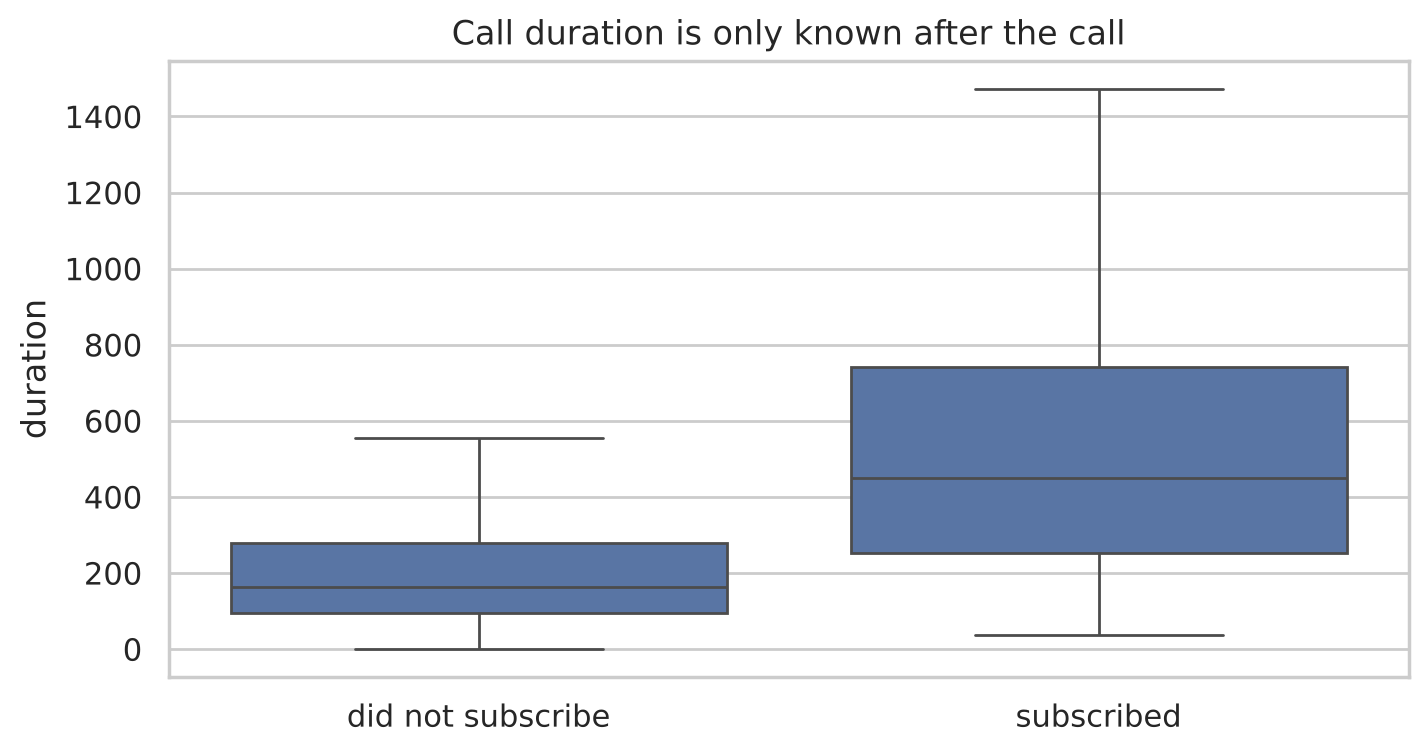

In [3]:
from sklearn.metrics import roc_auc_score

print(f"ROC AUC of duration alone: {roc_auc_score(bank['y'], bank['duration']):.3f}")
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=bank, x="y", y="duration", showfliers=False, ax=ax)
ax.set_xticks([0, 1], ["did not subscribe", "subscribed"])
ax.set_xlabel("")
ax.set_title("Call duration is only known after the call")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فقط با همین یک ستون، AUC حدود ۰٫۸ است؛ ولی این یک **توهم** است. قبل از تماس، مدت تماس را نمی‌دانیم. مدلی که با `duration` آموزش ببیند، در عمل بی‌فایده است. پس آن را حذف می‌کنیم. این دقیقاً همان قانون جلسهٔ ۲ است: **هر ویژگی باید در لحظهٔ پیش‌بینی در دسترس باشد.**

</div>

In [4]:
bank = bank.drop(columns="duration")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ستون `pdays` و مقدار ویژهٔ ۹۹۹

در `pdays` مقدار ۹۹۹ یعنی «قبلاً هرگز تماس نگرفته‌ایم»، نه ۹۹۹ روز. اگر آن را مثل یک عدد معمولی به مدل خطی بدهیم، گمراه‌کننده است. یک ویژگی صفر و یکی برای «قبلاً تماس گرفته شده» می‌سازیم و ۹۹۹ را با مقدار گمشده جایگزین می‌کنیم تا در Pipeline پر شود:

</div>

In [5]:
bank["contacted_before"] = (bank["pdays"] != 999).astype(int)
bank["pdays"] = bank["pdays"].replace(999, np.nan)
print(f"Contacted in a previous campaign: {bank['contacted_before'].mean():.1%}")

Contacted in a previous campaign: 3.7%


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. تحلیل اکتشافی هدفمند

چند سؤال که به انتخاب ویژگی و تفسیر مدل کمک می‌کنند:

</div>

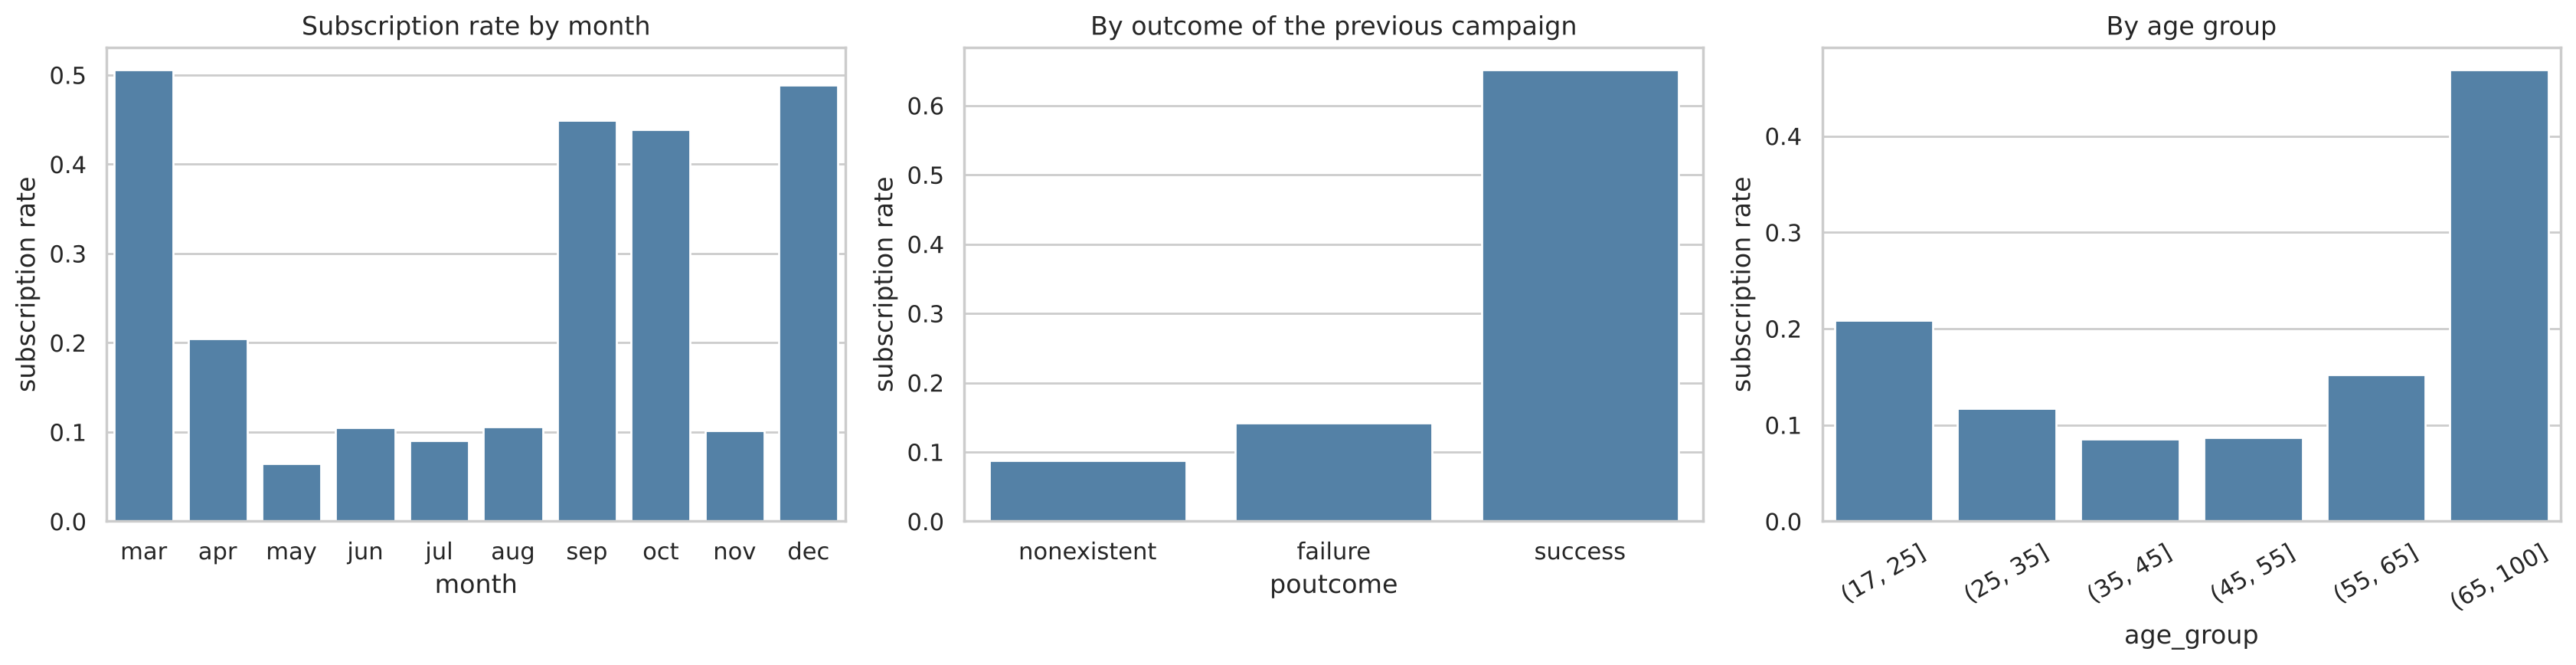

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
sns.barplot(data=bank, x="month", y="y", order=order, errorbar=None, color="steelblue", ax=axes[0])
axes[0].set_title("Subscription rate by month")
sns.barplot(data=bank, x="poutcome", y="y", errorbar=None, color="steelblue", ax=axes[1])
axes[1].set_title("By outcome of the previous campaign")
bank["age_group"] = pd.cut(bank["age"], [17, 25, 35, 45, 55, 65, 100])
sns.barplot(data=bank, x="age_group", y="y", errorbar=None, color="steelblue", ax=axes[2])
axes[2].set_title("By age group")
axes[2].tick_params(axis="x", rotation=30)
for ax in axes:
    ax.set_ylabel("subscription rate")
plt.tight_layout()
plt.show()
bank = bank.drop(columns="age_group")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- در ماه‌های مارس، سپتامبر، اکتبر و دسامبر نرخ موفقیت چند برابر است؛ ولی در این ماه‌ها تماس کمی گرفته شده است. ماه مه پرتماس‌ترین و کم‌بازده‌ترین ماه است.
- مشتریانی که در کمپین قبلی خرید کرده‌اند (`success`)، با احتمال بسیار بیشتری دوباره خرید می‌کنند.
- جوان‌ترها (دانشجویان) و بازنشسته‌ها بیشتر از میانسالان پاسخ مثبت می‌دهند؛ یک رابطهٔ **غیرخطی** که مدل‌های درختی بهتر از مدل خطی آن را می‌گیرند.

</div>

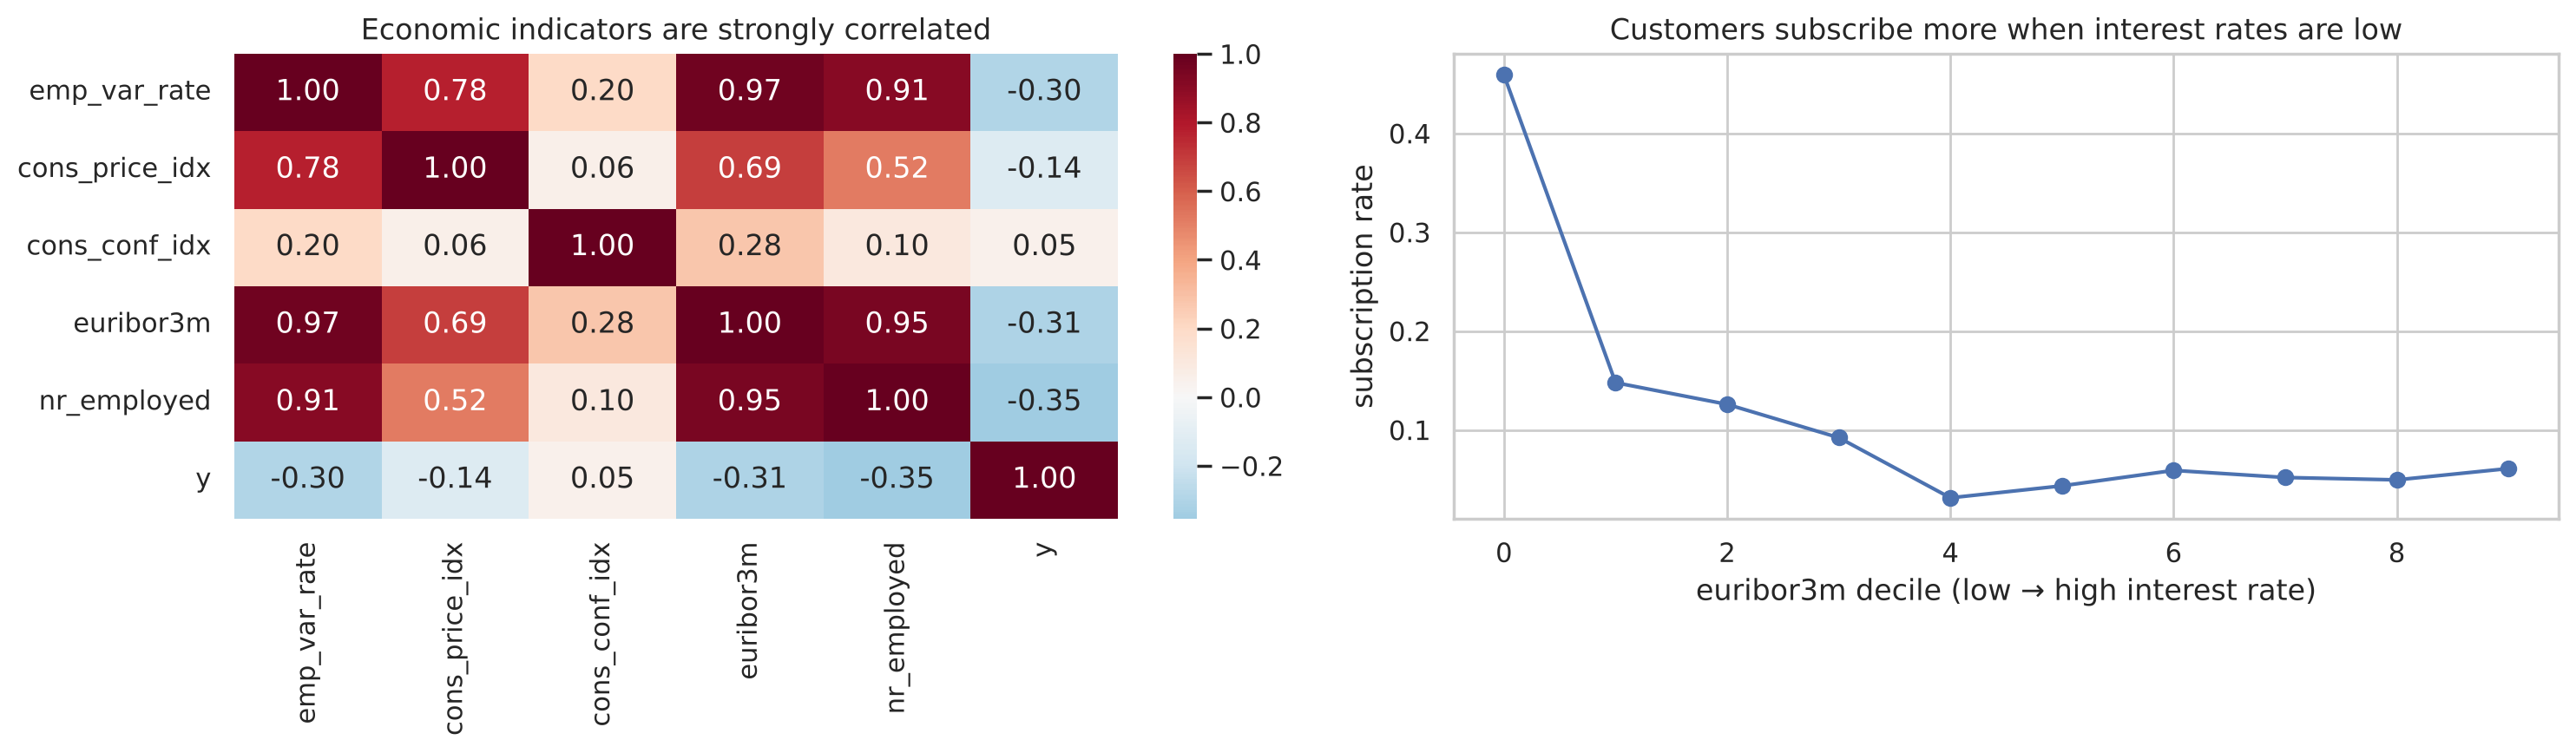

In [7]:
econ = ["emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(bank[econ + ["y"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Economic indicators are strongly correlated")
rate = bank.groupby(pd.qcut(bank["euribor3m"], 10, duplicates="drop"), observed=True)["y"].mean()
axes[1].plot(range(len(rate)), rate.values, "o-")
axes[1].set_xlabel("euribor3m decile (low → high interest rate)")
axes[1].set_ylabel("subscription rate")
axes[1].set_title("Customers subscribe more when interest rates are low")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

شاخص‌های اقتصادی با هم همبستگی بسیار شدیدی دارند (همه وضعیت کلی اقتصاد را نشان می‌دهند) و یکی از قوی‌ترین عوامل‌اند: در دوره‌هایی که نرخ بهره پایین بوده، مشتریان بیشتر سپرده خریده‌اند. برای مدل‌های درختی این هم‌خطی مشکلی ایجاد نمی‌کند، ولی تفسیر ضرایب مدل خطی را سخت می‌کند (جلسهٔ ۳).

## ۴. تقسیم داده و Pipeline

۲۰٪ داده را برای ارزیابی نهایی کنار می‌گذاریم و تا پایان پروژه به آن دست نمی‌زنیم.

</div>

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = bank.drop(columns="y")
y = bank["y"]
categorical = X.select_dtypes(exclude="number").columns.tolist()
numeric = X.select_dtypes("number").columns.tolist()
X[numeric] = X[numeric].astype(float)      # some tools (e.g. partial dependence) expect float features

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Categorical:", categorical)
print("Numeric:", numeric)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric: ['age', 'campaign', 'pdays', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'contacted_before']


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. مقایسهٔ مدل‌ها

چهار مدل را با **همان** پیش‌پردازش و **همان** تقسیم‌های اعتبارسنجی مقایسه می‌کنیم:

</div>

In [9]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

candidates = {
    "Baseline (prior)": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}
rows = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["average_precision", "roc_auc"], n_jobs=-1)
    rows.append({"model": name, "average precision": res["test_average_precision"].mean(),
                 "ROC AUC": res["test_roc_auc"].mean(), "fit time (s)": res["fit_time"].mean()})
pd.DataFrame(rows).set_index("model").round(3)

,average precision,ROC AUC,fit time (s)
model,,,
Baseline (prior),0.113,0.500,0.075
Logistic regression,0.449,0.789,0.264
Random forest,0.464,0.789,6.354
HistGradientBoosting,0.467,0.797,0.638


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- مدل پایه Average Precision حدود ۰٫۱۱ دارد؛ یعنی همان نرخ پایهٔ کلاس مثبت.
- همهٔ مدل‌ها بسیار بهتر از مدل پایه‌اند. HistGradientBoosting و جنگل تصادفی بهترین‌اند و HistGradientBoosting سریع‌تر است. آن را برای ادامه انتخاب می‌کنیم.
- بعد از حذف `duration`، AUC حدود ۰٫۸ است. این عدد واقع‌بینانه است؛ عدد بسیار بالاتر باید ما را به نشت داده مشکوک کند.

## ۶. تنظیم ابرپارامتر

</div>

In [10]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

hgb_pipe = Pipeline([("prep", preprocessor), ("model", HistGradientBoostingClassifier(random_state=42))])
search = RandomizedSearchCV(
    hgb_pipe,
    {
        "model__learning_rate": loguniform(0.02, 0.3),
        "model__max_leaf_nodes": randint(8, 64),
        "model__min_samples_leaf": randint(20, 200),
        "model__l2_regularization": loguniform(1e-3, 10),
        "model__max_iter": randint(100, 400),
    },
    n_iter=20, cv=cv, scoring="average_precision", n_jobs=-1, random_state=42,
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print({k.replace("model__", ""): (round(float(v), 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()})
print(f"Best CV average precision: {search.best_score_:.3f}")

{'l2_regularization': 0.0071, 'learning_rate': 0.0327, 'max_iter': 376, 'max_leaf_nodes': 40, 'min_samples_leaf': 77}
Best CV average precision: 0.469


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

تنظیم ابرپارامتر بهبود کوچکی داده است. این طبیعی است: Gradient Boosting با تنظیمات پیش‌فرض هم قوی است و بیشترین سود معمولاً از **ویژگی‌های خوب** و **تعریف درست مسئله** می‌آید، نه از تنظیم ابرپارامتر.

## ۷. از احتمال تا تصمیم: انتخاب آستانه بر اساس سود

مدل برای هر مشتری یک احتمال خرید می‌دهد. تصمیم کسب‌وکار این است: **با چه کسانی تماس بگیریم؟** با هزینهٔ ۵ برای هر تماس و سود ۵۰ برای هر فروش:

$$\text{Profit} = 50 \times TP - 5 \times (TP + FP)$$

آستانه را باید روی دادهٔ **آموزش** و با پیش‌بینی‌های **اعتبارسنجی متقابل** انتخاب کنیم (نه دادهٔ آزمون). `cross_val_predict` برای هر نمونه، احتمالی می‌دهد که مدلش آن نمونه را ندیده است:

</div>

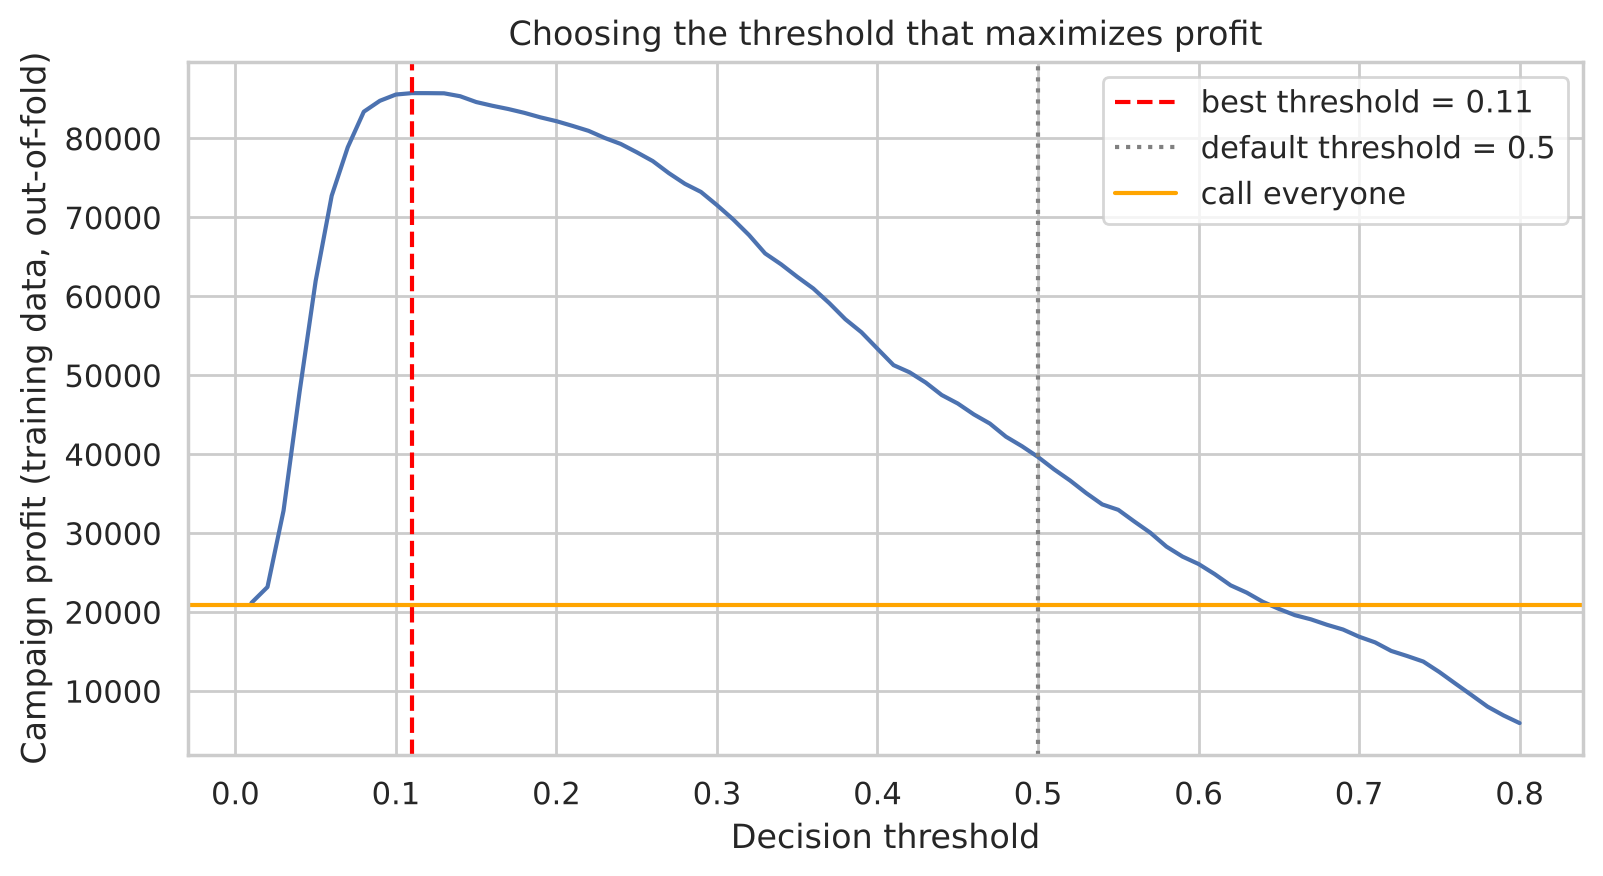

In [11]:
from sklearn.model_selection import cross_val_predict

CALL_COST, GAIN = 5, 50

def campaign_profit(y_true, call):
    tp = np.sum((call == 1) & (y_true == 1))
    n_calls = np.sum(call == 1)
    return GAIN * tp - CALL_COST * n_calls

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.linspace(0.01, 0.8, 80)
profits = [campaign_profit(y_train.values, (oof_proba >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmax(profits))]

plt.figure(figsize=(9, 4.5))
plt.plot(thresholds, profits)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"best threshold = {best_threshold:.2f}")
plt.axvline(0.5, color="gray", linestyle=":", label="default threshold = 0.5")
plt.axhline(campaign_profit(y_train.values, np.ones(len(y_train))), color="orange", label="call everyone")
plt.xlabel("Decision threshold")
plt.ylabel("Campaign profit (training data, out-of-fold)")
plt.title("Choosing the threshold that maximizes profit")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

آستانهٔ بهینه بسیار کمتر از ۰٫۵ است. چرا؟ چون از دست دادن یک خریدار (۵۰ واحد) ده برابر گران‌تر از یک تماس بی‌نتیجه (۵ واحد) است. از نظر تئوری، تماس وقتی سودآور است که $p \times 50 > 5$، یعنی $p > 0.1$؛ آستانه‌ای که پیدا کردیم به همین عدد نزدیک است.

## ۸. ارزیابی نهایی روی دادهٔ آزمون

حالا و فقط یک بار، مدل و آستانهٔ انتخاب‌شده را روی دادهٔ آزمون می‌سنجیم و با دو سیاست ساده مقایسه می‌کنیم: تماس با همه، و تماس با آستانهٔ پیش‌فرض ۰٫۵.

</div>

In [12]:
from sklearn.metrics import average_precision_score, classification_report

test_proba = best_model.predict_proba(X_test)[:, 1]
print(f"Test average precision: {average_precision_score(y_test, test_proba):.3f}")
print(f"Test ROC AUC:           {roc_auc_score(y_test, test_proba):.3f}\n")

policies = {
    "Call everyone": np.ones(len(y_test), dtype=int),
    "Model, threshold 0.5": (test_proba >= 0.5).astype(int),
    f"Model, threshold {best_threshold:.2f}": (test_proba >= best_threshold).astype(int),
}
pd.DataFrame([{
    "policy": name,
    "calls": int(call.sum()),
    "subscriptions": int(((call == 1) & (y_test.values == 1)).sum()),
    "share of all buyers reached": ((call == 1) & (y_test.values == 1)).sum() / y_test.sum(),
    "profit": campaign_profit(y_test.values, call),
} for name, call in policies.items()]).set_index("policy").round(3)

Test average precision: 0.494
Test ROC AUC:           0.817



,calls,subscriptions,share of all buyers reached,profit
policy,,,,
Call everyone,8238,928,1.000,5210
"Model, threshold 0.5",340,234,0.252,10000
"Model, threshold 0.11",1602,615,0.663,22740


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- **تماس با همه** هزینهٔ زیادی دارد، چون بیشتر تماس‌ها بی‌نتیجه‌اند.
- **آستانهٔ ۰٫۵** محافظه‌کارانه است: تماس‌های کمی می‌گیرد و بیشتر خریداران را از دست می‌دهد.
- **آستانهٔ بهینه** با تماس با بخشی از مشتریان، بخش بزرگی از خریداران را پیدا می‌کند و بیشترین سود را دارد.

### نمودار بهره (Gain Chart)

مدیران معمولاً این سؤال را می‌پرسند: «اگر فقط با ۲۰٪ مشتریان تماس بگیریم، چند درصد خریداران را پیدا می‌کنیم؟» مشتریان را بر اساس احتمال پیش‌بینی‌شده مرتب می‌کنیم:

</div>

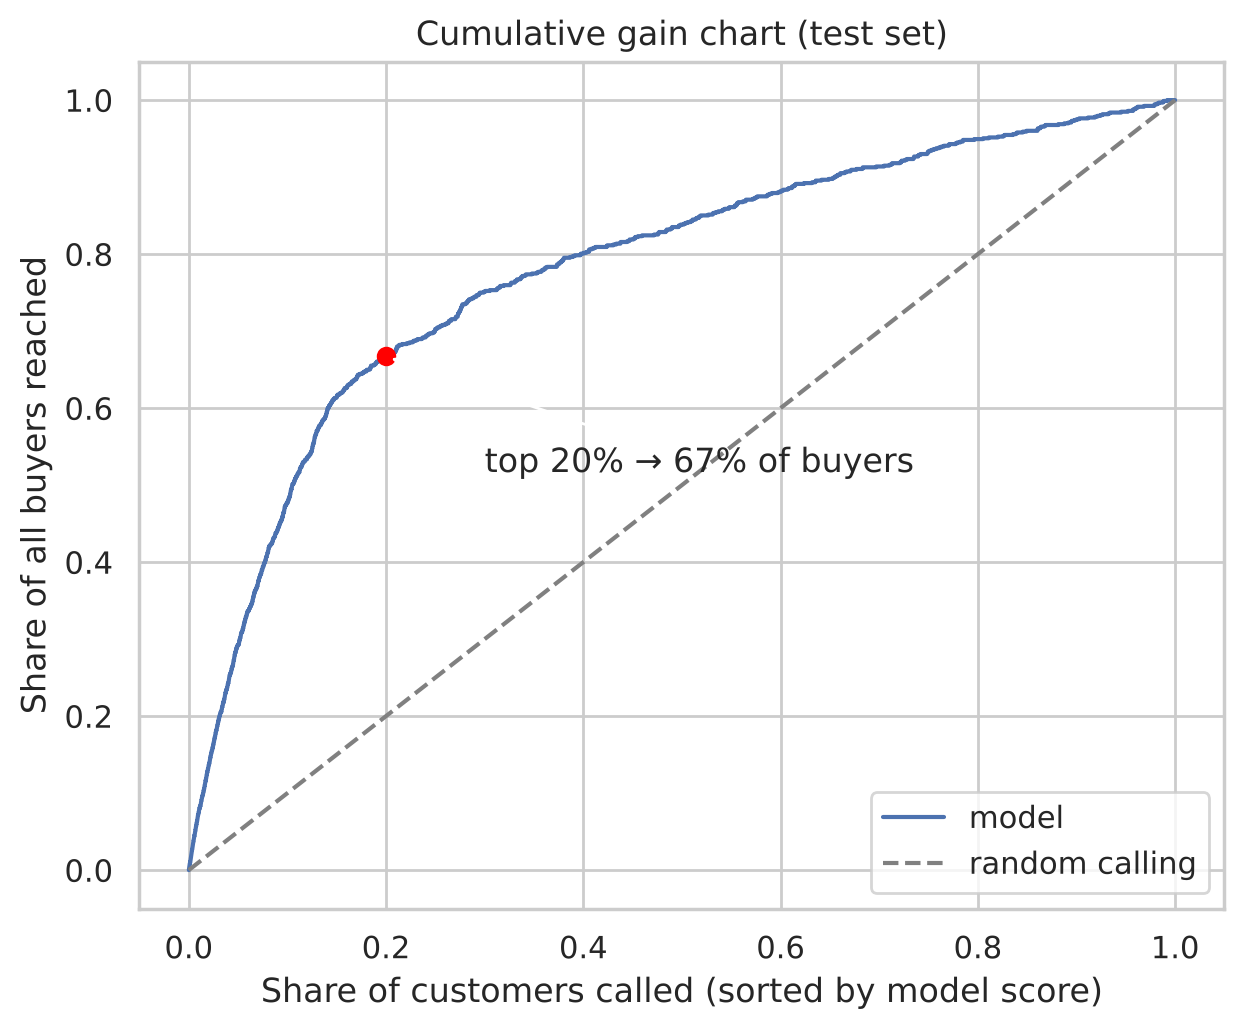

In [13]:
order_idx = np.argsort(-test_proba)
cum_buyers = np.cumsum(y_test.values[order_idx]) / y_test.sum()
share_called = np.arange(1, len(y_test) + 1) / len(y_test)

plt.figure(figsize=(7, 5.5))
plt.plot(share_called, cum_buyers, label="model")
plt.plot([0, 1], [0, 1], "--", color="gray", label="random calling")
at20 = cum_buyers[int(0.2 * len(y_test)) - 1]
plt.scatter([0.2], [at20], color="red", zorder=3)
plt.annotate(f"top 20% → {at20:.0%} of buyers", (0.2, at20), xytext=(0.3, at20 - 0.15),
             arrowprops=dict(arrowstyle="->"))
plt.xlabel("Share of customers called (sorted by model score)")
plt.ylabel("Share of all buyers reached")
plt.title("Cumulative gain chart (test set)")
plt.legend(loc="lower right")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با تماس فقط با ۲۰٪ مشتریانی که مدل بیشترین احتمال را برایشان پیش‌بینی کرده، حدود دوسوم کل خریداران پیدا می‌شوند؛ در حالی که تماس تصادفی فقط ۲۰٪ آن‌ها را پیدا می‌کند. این نمودار برای ارائه به مدیران بسیار گویاتر از AUC است.

## ۹. تفسیر مدل

### کدام ویژگی‌ها مهم‌اند؟

</div>

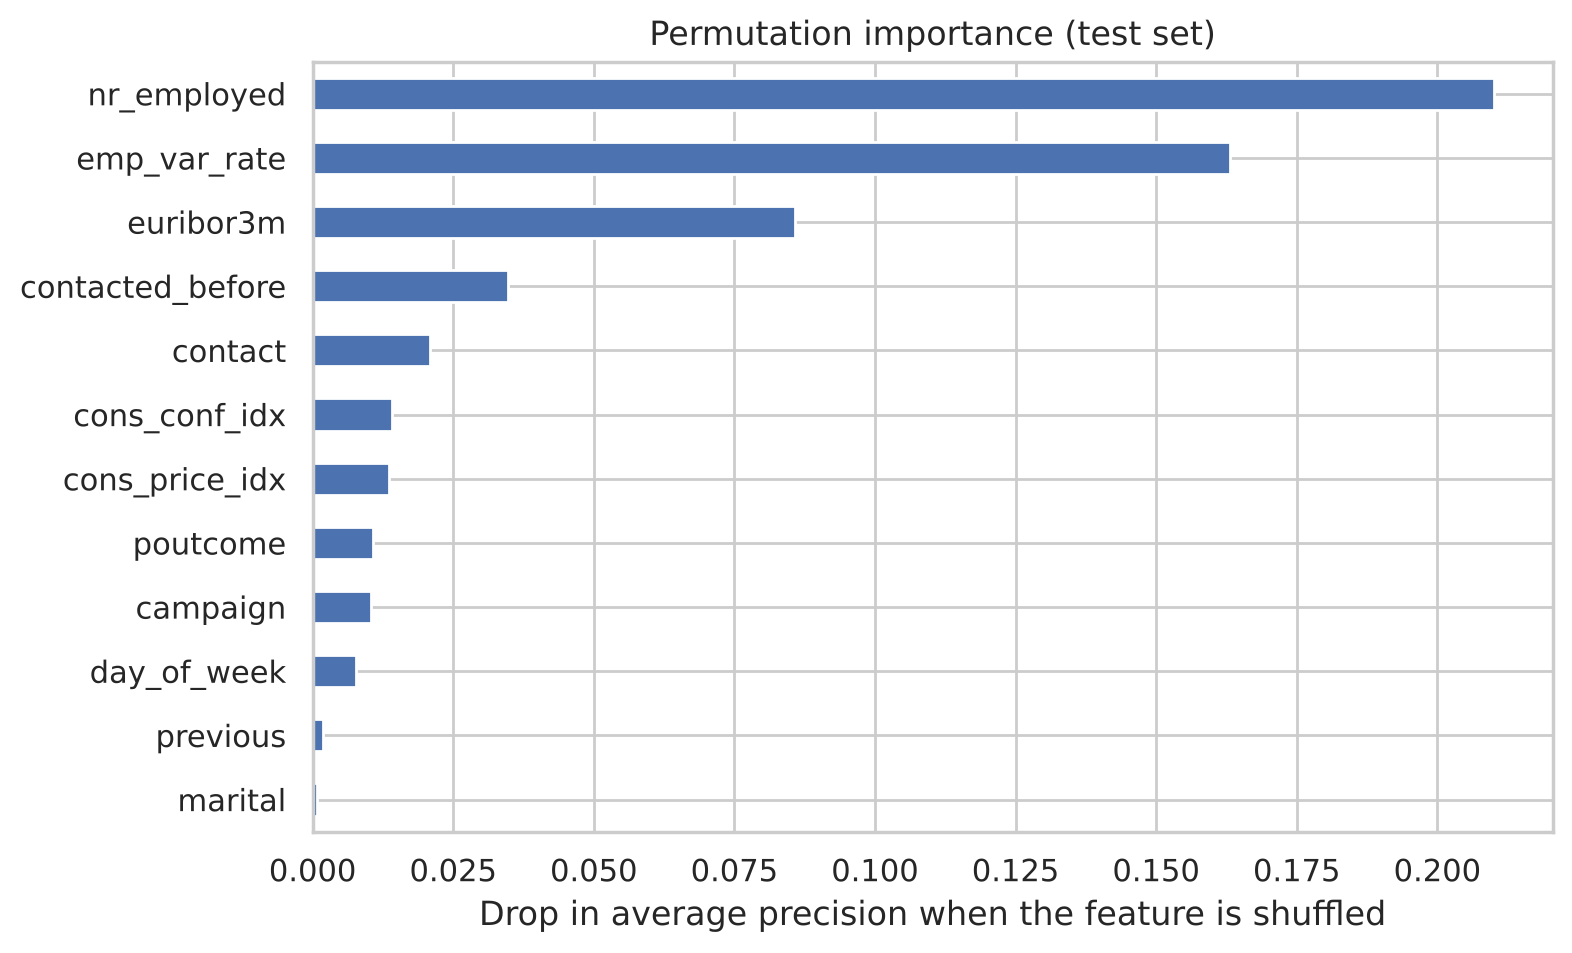

In [14]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.tail(12).plot.barh(figsize=(8, 5))
plt.xlabel("Drop in average precision when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

شاخص‌های اقتصادی (`nr_employed`، `emp_var_rate` و `euribor3m`)، سابقهٔ تماس در کمپین قبلی و نوع تماس (موبایل یا تلفن ثابت) مهم‌ترین عوامل‌اند. چون شاخص‌های اقتصادی با هم همبسته‌اند، اهمیت بینشان تقسیم می‌شود؛ اگر یکی را بُر بزنیم، مدل تا حدی از بقیه استفاده می‌کند.

### نمودار وابستگی جزئی (Partial Dependence)

نمودار وابستگی جزئی نشان می‌دهد پیش‌بینی مدل، به‌طور میانگین، با تغییر یک ویژگی (با ثابت ماندن بقیه) چطور تغییر می‌کند:

</div>

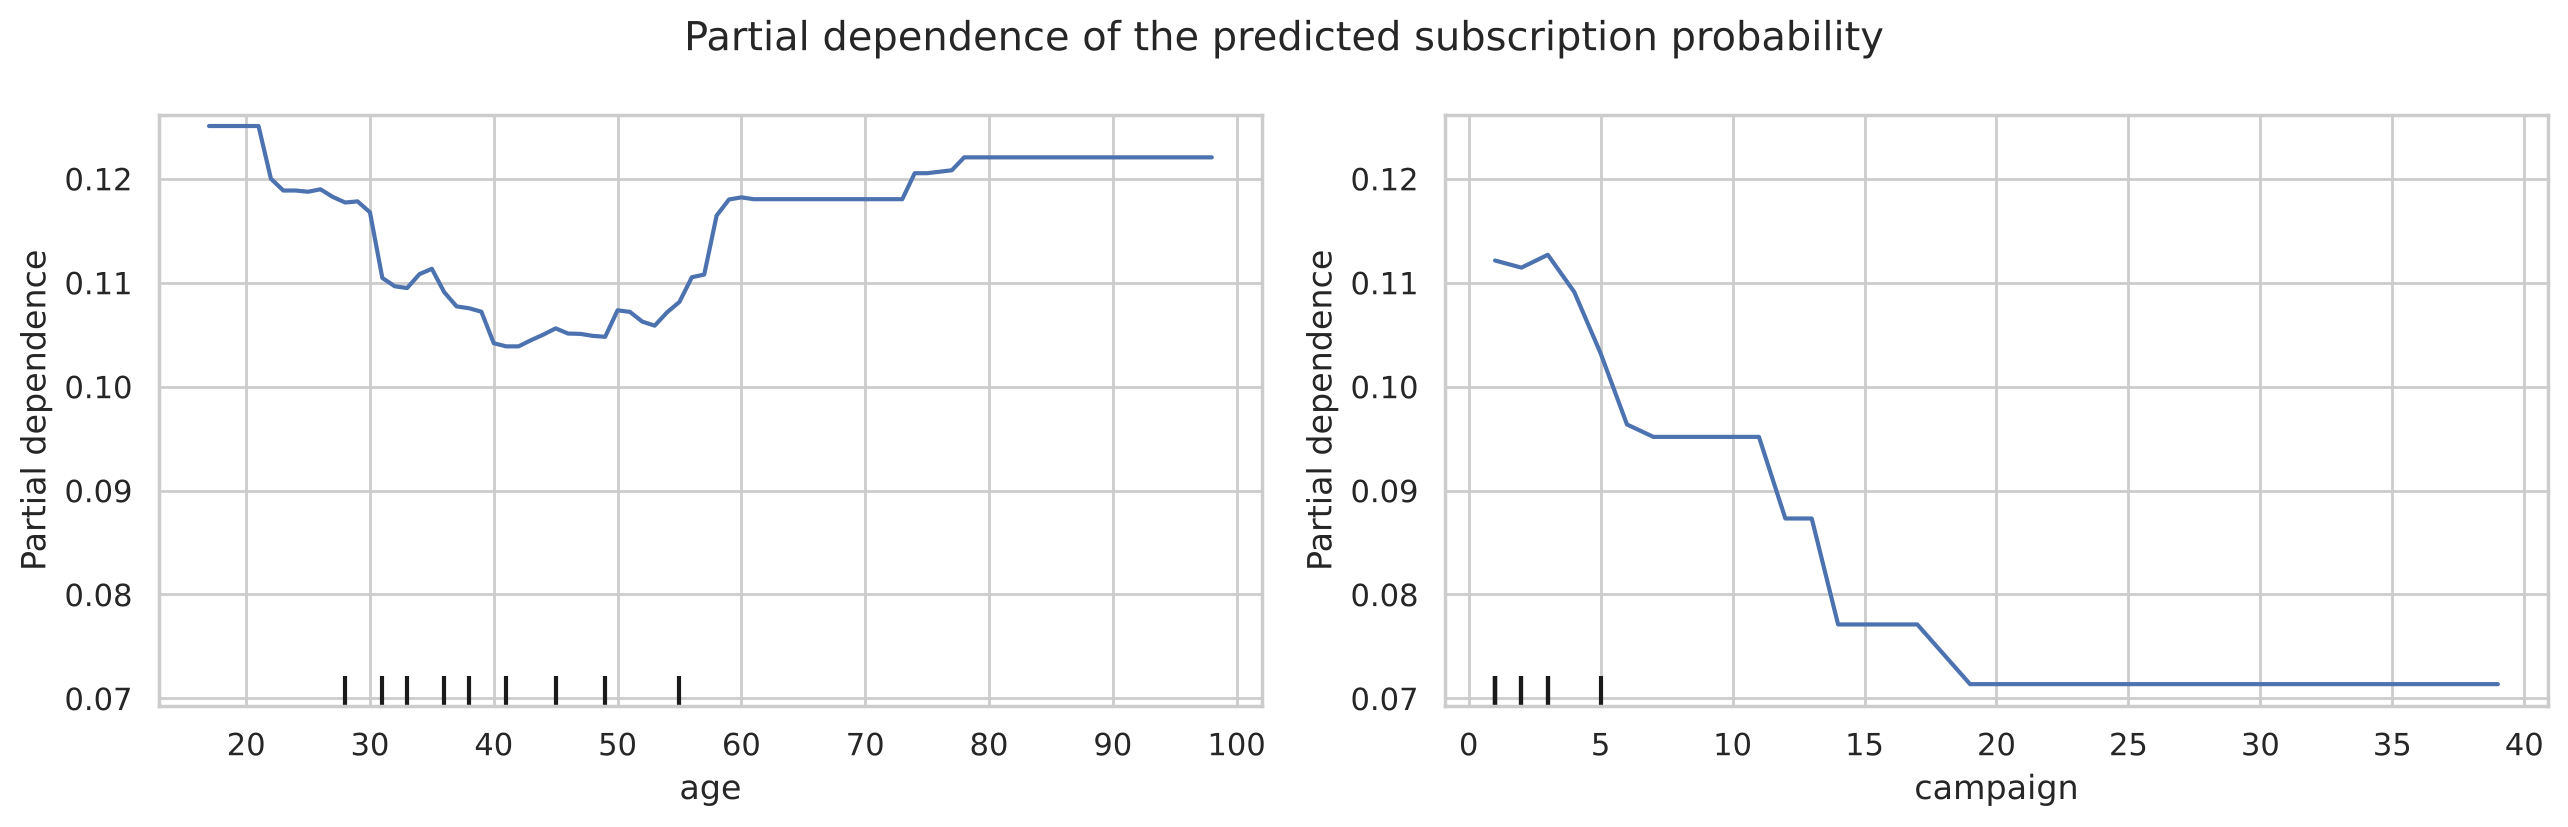

In [15]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
PartialDependenceDisplay.from_estimator(best_model, X_test.sample(3000, random_state=0),
                                        ["age", "campaign"], ax=ax)
fig.suptitle("Partial dependence of the predicted subscription probability")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- اثر سن تقریباً **U شکل** است: جوان‌ترین و مسن‌ترین مشتریان احتمال خرید بیشتری دارند.
- تماس‌های مکرر در یک کمپین (`campaign` زیاد) احتمال خرید را کم می‌کند؛ پیام عملی: بیش از چند بار با یک مشتری تماس نگیرید.

**هشدار:** برای ویژگی‌هایی که همبستگی شدید دارند (مثل شاخص‌های اقتصادی)، نمودار وابستگی جزئی گمراه‌کننده است، چون ترکیب‌هایی را می‌سازد که در واقعیت رخ نمی‌دهند (مثلاً نرخ بهرهٔ بالا با اشتغال پایین). به همین دلیل آن‌ها را اینجا رسم نکردیم.

**یادآوری:** این‌ها رفتار **مدل** را توصیف می‌کنند، نه رابطهٔ علّی را. برای ادعای علّی (مثلاً «اگر کمتر تماس بگیریم، فروش بیشتر می‌شود»)، آزمایش A/B لازم است (ترم علم داده، جلسهٔ ۹).

## ۱۰. ذخیرهٔ مدل و استفاده در برنامه

مدل نهایی را روی **همهٔ دادهٔ آموزش** آموزش دیده داریم. Pipeline شامل پیش‌پردازش هم هست، پس فایل ذخیره‌شده دادهٔ **خام** می‌گیرد. آستانه را هم کنار مدل ذخیره می‌کنیم:

</div>

In [16]:
import joblib

joblib.dump({"model": best_model, "threshold": float(best_threshold)}, "bank_marketing_model.joblib")

loaded = joblib.load("bank_marketing_model.joblib")
new_customer = pd.DataFrame([{
    "age": 67, "job": "retired", "marital": "married", "education": "university.degree",
    "default": "no", "housing": "yes", "loan": "no", "contact": "cellular", "month": "oct",
    "day_of_week": "tue", "campaign": 1, "pdays": np.nan, "previous": 1, "poutcome": "success",
    "emp_var_rate": -1.8, "cons_price_idx": 92.9, "cons_conf_idx": -46.2, "euribor3m": 1.3,
    "nr_employed": 5099.1, "contacted_before": 1,
}])
p = loaded["model"].predict_proba(new_customer)[0, 1]
print(f"Predicted probability of subscribing: {p:.2f}")
print("Decision:", "call" if p >= loaded["threshold"] else "do not call")

Predicted probability of subscribing: 0.18
Decision: call


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

این فایل همان چیزی است که در ترم ششم، داخل یک سرویس **FastAPI** قرار می‌دهیم تا برنامه‌های دیگر بتوانند با یک درخواست ساده از آن پیش‌بینی بگیرند.

**نکتهٔ مهم برای استقرار:** `joblib` فایل را با همان نسخهٔ scikit-learn بارگذاری می‌کند که با آن ذخیره شده است. نسخهٔ کتابخانه‌ها را در `requirements.txt` ثابت کنید.

## ۱۱. گزارش پروژه برای مدیر

1. **مدل، سود کمپین را افزایش می‌دهد.** با تماس فقط با مشتریانی که احتمال خریدشان از آستانهٔ انتخاب‌شده بیشتر است، سود از سیاست «تماس با همه» بیشتر می‌شود و تعداد تماس‌ها به‌شدت کم می‌شود.
2. **با ۲۰٪ تماس، حدود دوسوم خریداران پیدا می‌شوند.**
3. **زمان کمپین مهم است:** وقتی نرخ بهره پایین است، مشتریان بیشتر سپرده می‌خرند.
4. **مشتریان راضی کمپین قبلی** بهترین هدف‌اند.
5. **تماس‌های مکرر بی‌فایده است.**
6. **محدودیت‌ها:** داده مربوط به ۲۰۰۸ تا ۲۰۱۰ است و شرایط اقتصادی عوض شده؛ مدل باید با دادهٔ جدید دوباره آموزش ببیند و عملکردش پایش شود. هزینه و سود فرضی‌اند و باید با عددهای واقعی بانک جایگزین شوند.

## جمع‌بندی

- یک پروژهٔ موفق با **تعریف دقیق مسئله** شروع می‌شود: هدف، لحظهٔ پیش‌بینی و معیار موفقیت.
- ویژگی‌هایی را که در لحظهٔ پیش‌بینی در دسترس نیستند (مثل `duration`) حذف کنید، حتی اگر دقت را بالا ببرند.
- مدل‌ها را با Pipeline و اعتبارسنجی متقابل یکسان مقایسه کنید و دادهٔ آزمون را برای پایان نگه دارید.
- آستانه را بر اساس **هزینه و سود واقعی** و با پیش‌بینی‌های اعتبارسنجی متقابل انتخاب کنید.
- نتیجه را به زبان کسب‌وکار گزارش کنید: سود، نمودار بهره و عوامل اصلی.
- مدل را همراه با پیش‌پردازش و آستانه ذخیره کنید تا در محصول قابل استفاده باشد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. همین پروژه را یک بار **با** ستون `duration` اجرا کنید و Average Precision را گزارش کنید. چرا این عدد در عمل بی‌ارزش است؟

۲. فرض کنید هزینهٔ هر تماس ۱۰ و سود هر فروش ۳۰ باشد. آستانهٔ بهینه و سود روی دادهٔ آزمون را دوباره حساب کنید.

۳. مدل `LogisticRegression(class_weight="balanced")` را با همین Pipeline آموزش دهید و نمودار بهرهٔ آن را با مدل HistGradientBoosting روی یک نمودار مقایسه کنید.

۴. ستون‌های شاخص اقتصادی را حذف کنید و مدل را دوباره ارزیابی کنید. Average Precision چقدر افت می‌کند؟ این نتیجه دربارهٔ استفاده از مدل در شرایط اقتصادی جدید چه می‌گوید؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** همین پروژه را یک بار **با** ستون `duration` اجرا کنید و Average Precision را گزارش کنید. چرا این عدد در عمل بی‌ارزش است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** فرض کنید هزینهٔ هر تماس ۱۰ و سود هر فروش ۳۰ باشد. آستانهٔ بهینه و سود روی دادهٔ آزمون را دوباره حساب کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** مدل `LogisticRegression(class_weight="balanced")` را با همین Pipeline آموزش دهید و نمودار بهرهٔ آن را با مدل HistGradientBoosting روی یک نمودار مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** ستون‌های شاخص اقتصادی را حذف کنید و مدل را دوباره ارزیابی کنید. Average Precision چقدر افت می‌کند؟ این نتیجه دربارهٔ استفاده از مدل در شرایط اقتصادی جدید چه می‌گوید؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
